In [78]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from itertools import cycle
import math

In [106]:
data_dir = Path("data/cluster_chain_n4_e-4.0000/")

instances = pd.read_csv(data_dir / "instances.csv")
instances

,Unnamed: 0,lambda,n_updates,h_file,start_temp,end_temp,trial,out_file
0,0,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,0,data/cluster_chain_n4_e-4.0000/out_l1.0_t0.csv
1,1,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,1,data/cluster_chain_n4_e-4.0000/out_l1.0_t1.csv
2,2,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,2,data/cluster_chain_n4_e-4.0000/out_l1.0_t2.csv
3,3,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,3,data/cluster_chain_n4_e-4.0000/out_l1.0_t3.csv
4,4,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,4,data/cluster_chain_n4_e-4.0000/out_l1.0_t4.csv
5,5,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,5,data/cluster_chain_n4_e-4.0000/out_l1.0_t5.csv
6,6,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,6,data/cluster_chain_n4_e-4.0000/out_l1.0_t6.csv
7,7,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,7,data/cluster_chain_n4_e-4.0000/out_l1.0_t7.csv
8,8,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,8,data/cluster_chain_n4_e-4.0000/out_l1.0_t8.csv
9,9,1.0,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,9,data/cluster_chain_n4_e-4.0000/out_l1.0_t9.csv


skipping row


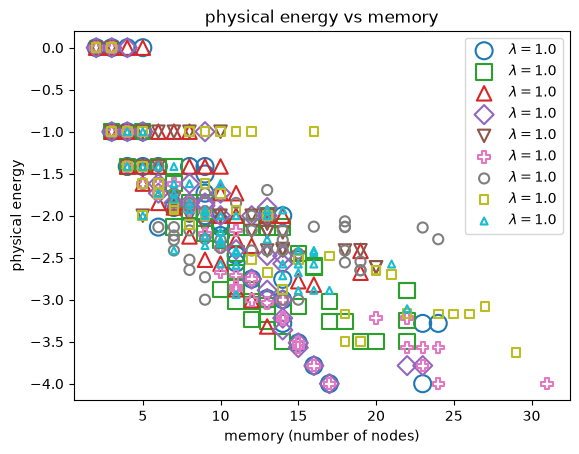

In [130]:
markers = cycle(["o", "s", "^", "D", "v", "P"])
# Scales marker area (points^2) from outer ring to inner ring based on series count
sizes = np.linspace(150, 25, len(instances))

fig, ax = plt.subplots()

keep_indices = [0, 3, 7]

final_states = []

for i, (index, row) in enumerate(instances.iterrows()):
    if not Path(row["out_file"]).exists():
        print("skipping row")
        continue

    # if index not in keep_indices:
        # continue

    this_data = pd.read_csv(row["out_file"]).drop_duplicates(["memory", "energy"])
    color = f"C{i % 10}"  # Explicitly grab Matplotlib's default color cycle

    ax.scatter(
        this_data["memory"],
        this_data["energy"],
        s=sizes[i],
        marker=next(markers),
        facecolors="none",
        edgecolors=color,
        linewidths=1.5,
        label=f"$\\lambda = {row['lambda']}$",
    )

    final_states.append({
        "lambda": row["lambda"],
        "energy": this_data["energy"].iloc[-1],
        "memory": this_data["memory"].iloc[-1],
        "free_energy": this_data["free_energy"].iloc[-1]
    })

ax.legend()
plt.title("physical energy vs memory")
plt.xlabel("memory (number of nodes)")
plt.ylabel("physical energy")
plt.show()

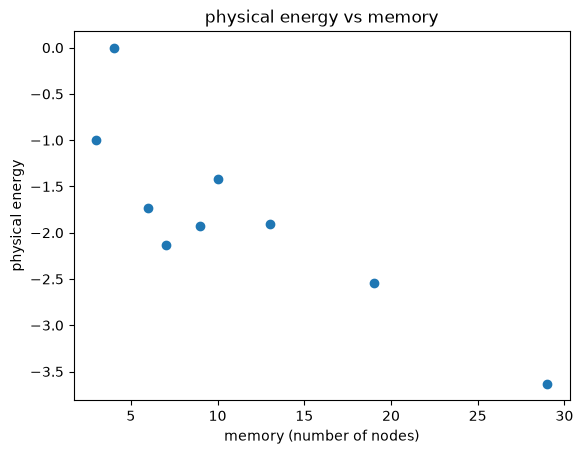

In [131]:
final_states_df = pd.DataFrame(final_states)
final_states_df

plt.scatter(final_states_df["memory"], final_states_df["energy"])
plt.title("physical energy vs memory")
plt.xlabel("memory (number of nodes)")
plt.ylabel("physical energy")
plt.show()

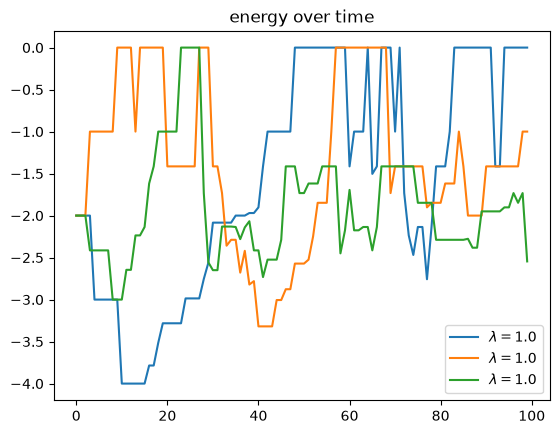

In [132]:
for index, row in instances.iterrows():
    if not Path(row["out_file"]).exists():
        continue

    if not index in keep_indices:
        continue

    this_data = pd.read_csv(row["out_file"])

    plt.plot(this_data.index, this_data["energy"], label=f"$\\lambda={row["lambda"]}$")

plt.title("energy over time")
plt.legend()

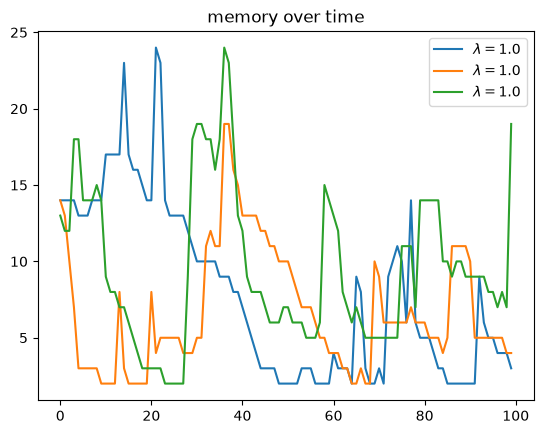

In [127]:
for index, row in instances.iterrows():
    if not Path(row["out_file"]).exists():
        continue

    if not index in keep_indices:
        continue

    this_data = pd.read_csv(row["out_file"])

    plt.plot(this_data.index, this_data["memory"], label=f"$\\lambda={row["lambda"]}$")

plt.title("memory over time")
plt.legend()